In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/processed/train.csv")

df.head()

Matplotlib is building the font cache; this may take a moment.


,datetime,streetname,hour,weekday,temperature,weather_condition,incidents,n_pedestrians,towards_ratio,lag_1h,lag_2h,lag_3h,lag_24h,lag_168h,target_datetime,n_pedestrians_next_hour
0,2022-10-06 00:00:00,Kaiserstrasse,0,Thursday,15,partly-cloudy-night,no_incident,26,0.576923,92.0,173.0,234.0,50.0,57.0,2022-10-06 01:00:00,13
1,2022-10-06 01:00:00,Kaiserstrasse,1,Thursday,15,partly-cloudy-night,no_incident,13,0.769231,26.0,92.0,173.0,11.0,32.0,2022-10-06 02:00:00,13
2,2022-10-06 02:00:00,Kaiserstrasse,2,Thursday,14,clear-night,no_incident,13,0.461538,13.0,26.0,92.0,6.0,4.0,2022-10-06 03:00:00,14
3,2022-10-06 03:00:00,Kaiserstrasse,3,Thursday,14,clear-night,no_incident,14,0.285714,13.0,13.0,26.0,15.0,14.0,2022-10-06 04:00:00,21
4,2022-10-06 04:00:00,Kaiserstrasse,4,Thursday,13,clear-night,no_incident,21,0.238095,14.0,13.0,13.0,23.0,16.0,2022-10-06 05:00:00,58


In [2]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum())

Shape: (37320, 16)

Columns:
['datetime', 'streetname', 'hour', 'weekday', 'temperature', 'weather_condition', 'incidents', 'n_pedestrians', 'towards_ratio', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_168h', 'target_datetime', 'n_pedestrians_next_hour']

Data types:
datetime                       str
streetname                     str
hour                         int64
weekday                        str
temperature                  int64
weather_condition              str
incidents                      str
n_pedestrians                int64
towards_ratio              float64
lag_1h                     float64
lag_2h                     float64
lag_3h                     float64
lag_24h                    float64
lag_168h                   float64
target_datetime                str
n_pedestrians_next_hour      int64
dtype: object

Missing values:
datetime                   0
streetname                 0
hour                       0
weekday                    0
temperature            

In [3]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum())

Shape: (37320, 16)

Columns:
['datetime', 'streetname', 'hour', 'weekday', 'temperature', 'weather_condition', 'incidents', 'n_pedestrians', 'towards_ratio', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_24h', 'lag_168h', 'target_datetime', 'n_pedestrians_next_hour']

Missing values:
datetime                   0
streetname                 0
hour                       0
weekday                    0
temperature                0
weather_condition          0
incidents                  0
n_pedestrians              0
towards_ratio              0
lag_1h                     0
lag_2h                     0
lag_3h                     0
lag_24h                    0
lag_168h                   0
target_datetime            0
n_pedestrians_next_hour    0
dtype: int64


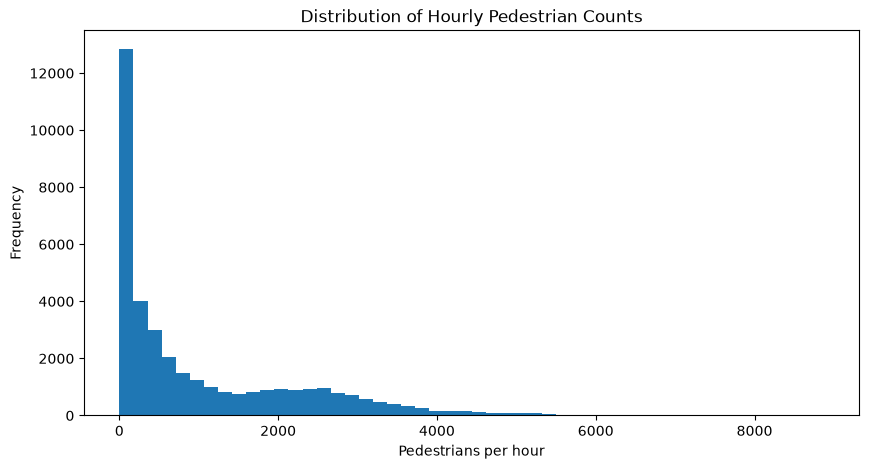

In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["n_pedestrians"],
    bins=50
)

plt.xlabel("Pedestrians per hour")
plt.ylabel("Frequency")
plt.title("Distribution of Hourly Pedestrian Counts")

plt.show()

Observation: The hourly pedestrian-count distribution is highly right-skewed. A large number of observations have relatively low pedestrian counts, while a smaller number of observations have substantially higher counts, extending up to approximately 8,874 pedestrians per hour. This indicates that pedestrian flow varies considerably across time and locations and that high-traffic periods may have a significant influence on model training.

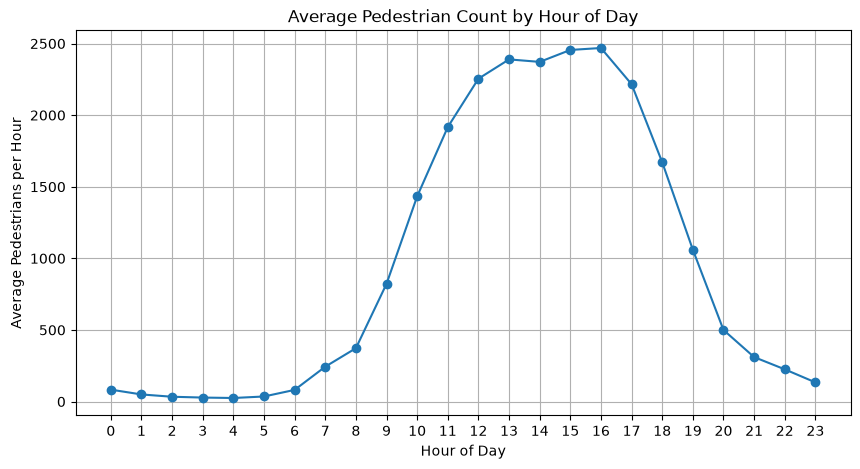

In [6]:
hourly_avg = (
    df.groupby("hour")["n_pedestrians"]
    .mean()
)

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_avg.index,
    hourly_avg.values,
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Average Pedestrian Count by Hour of Day")
plt.xticks(range(24))
plt.grid(True)

plt.show()

### Observation: Hourly Pedestrian Pattern

Pedestrian flow shows a strong dependence on the hour of the day. Activity is very low during the early morning hours and increases substantially from the morning onward. The highest average pedestrian counts occur during the afternoon, approximately between 13:00 and 16:00, followed by a decline during the evening and nighttime.

This indicates that time-of-day is an important feature for pedestrian-flow forecasting.

In [4]:
df[
    [
        "n_pedestrians",
        "lag_1h",
        "lag_2h",
        "lag_3h",
        "lag_24h",
        "lag_168h",
        "n_pedestrians_next_hour",
    ]
].describe()

,n_pedestrians,lag_1h,lag_2h,lag_3h,lag_24h,lag_168h,n_pedestrians_next_hour
count,37320.000000,37320.000000,37320.000000,37320.000000,37320.000000,37320.000000,37320.000000
mean,1029.212781,1030.018569,1029.881592,1028.921383,1028.868837,1030.934271,1027.159512
std,1238.756587,1238.094406,1238.212090,1238.978190,1238.596870,1240.731278,1240.326222
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,81.000000,83.000000,83.000000,79.000000,80.000000,81.000000,76.000000
50%,459.000000,460.000000,460.000000,459.500000,459.000000,460.000000,455.000000
75%,1763.250000,1763.000000,1763.000000,1763.000000,1764.000000,1767.000000,1764.000000
max,8874.000000,8874.000000,8874.000000,8874.000000,8874.000000,8874.000000,8874.000000


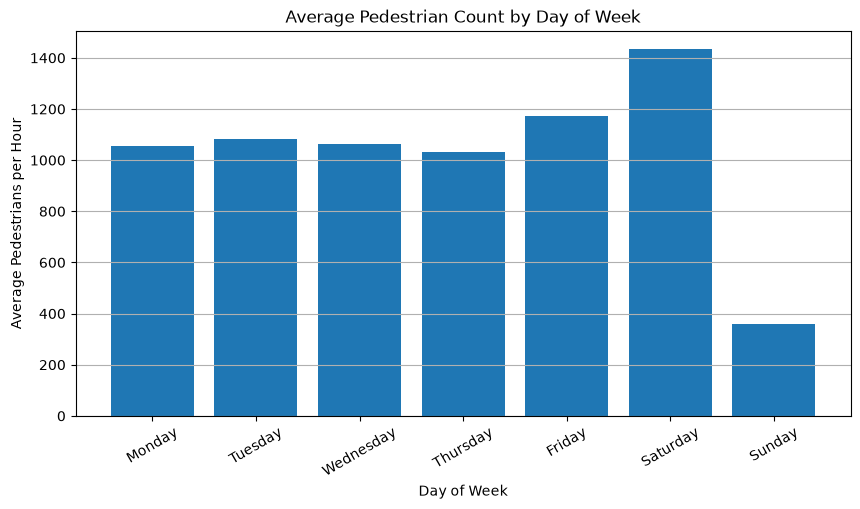

In [7]:
weekday_avg = (
    df.groupby("weekday")["n_pedestrians"]
    .mean()
)

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_avg = weekday_avg.reindex(weekday_order)

plt.figure(figsize=(10, 5))

plt.bar(
    weekday_avg.index,
    weekday_avg.values
)

plt.xlabel("Day of Week")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Average Pedestrian Count by Day of Week")

plt.xticks(rotation=30)
plt.grid(axis="y")

plt.show()

### Observation: Day-of-Week Pattern

Pedestrian flow varies considerably across the days of the week. Saturday has the highest average pedestrian count, followed by Friday, while Sunday has substantially lower pedestrian activity than the other days. Monday through Thursday show relatively similar average pedestrian counts.

This indicates that weekday information may provide useful predictive information for pedestrian-flow forecasting.

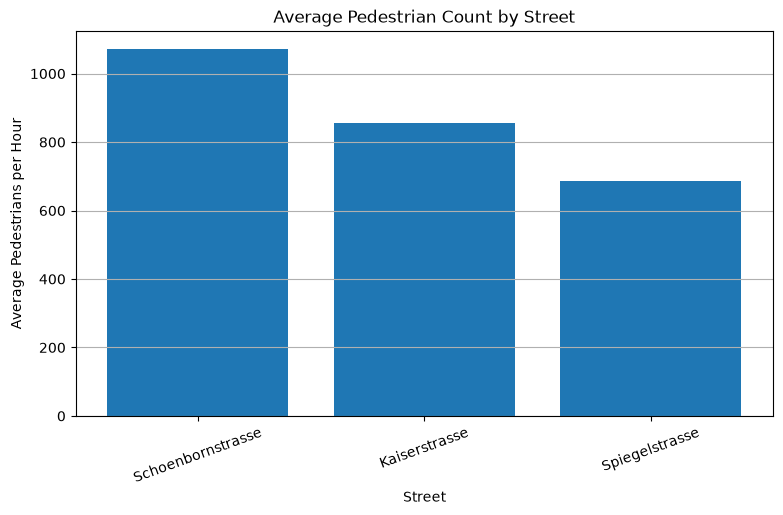

In [8]:
street_avg = (
    df.groupby("streetname")["n_pedestrians"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    street_avg.index,
    street_avg.values
)

plt.xlabel("Street")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Average Pedestrian Count by Street")

plt.xticks(rotation=20)
plt.grid(axis="y")

plt.show()

### Observation: Street-Level Variation

Average pedestrian flow differs substantially between the three streets. Schoenbornstrasse has the highest average pedestrian count, followed by Kaiserstrasse and Spiegelstrasse. This indicates that location-specific characteristics influence pedestrian flow and that street identity should be retained as a predictive feature.

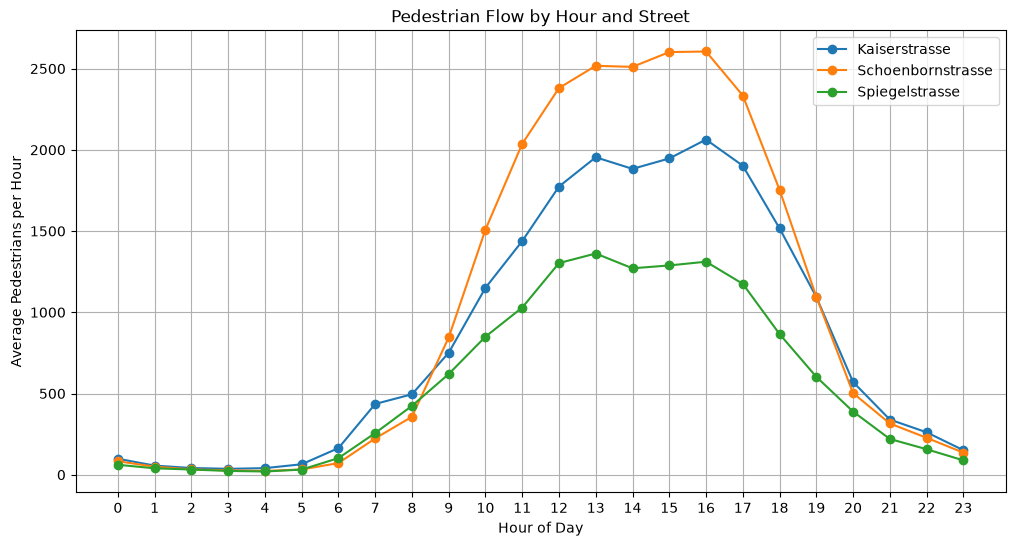

In [9]:
street_hour_avg = (
    df.groupby(["hour", "streetname"])["n_pedestrians"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

for street in street_hour_avg["streetname"].unique():
    street_data = street_hour_avg[
        street_hour_avg["streetname"] == street
    ]

    plt.plot(
        street_data["hour"],
        street_data["n_pedestrians"],
        marker="o",
        label=street
    )

plt.xlabel("Hour of Day")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Pedestrian Flow by Hour and Street")
plt.xticks(range(24))
plt.legend()
plt.grid(True)

plt.show()

### Observation: Interaction Between Street and Hour

Pedestrian flow exhibits a strong daily pattern across all three streets, with activity generally increasing during the day and reaching its highest levels during the afternoon. However, the magnitude and detailed shape of this pattern vary by street. Schoenbornstrasse consistently records the highest pedestrian volume, while Spiegelstrasse records the lowest.

This indicates that both street location and time of day are important predictive variables. The variation between streets also suggests that the effect of time may be location-dependent.

In [10]:
lag_columns = [
    "n_pedestrians",
    "lag_1h",
    "lag_2h",
    "lag_3h",
    "lag_24h",
    "lag_168h",
    "n_pedestrians_next_hour",
]

correlation = df[lag_columns].corr()

correlation["n_pedestrians_next_hour"].sort_values(
    ascending=False
)

n_pedestrians_next_hour    1.000000
n_pedestrians              0.951206
lag_168h                   0.864464
lag_1h                     0.830907
lag_24h                    0.671061
lag_2h                     0.663237
lag_3h                     0.470001
Name: n_pedestrians_next_hour, dtype: float64

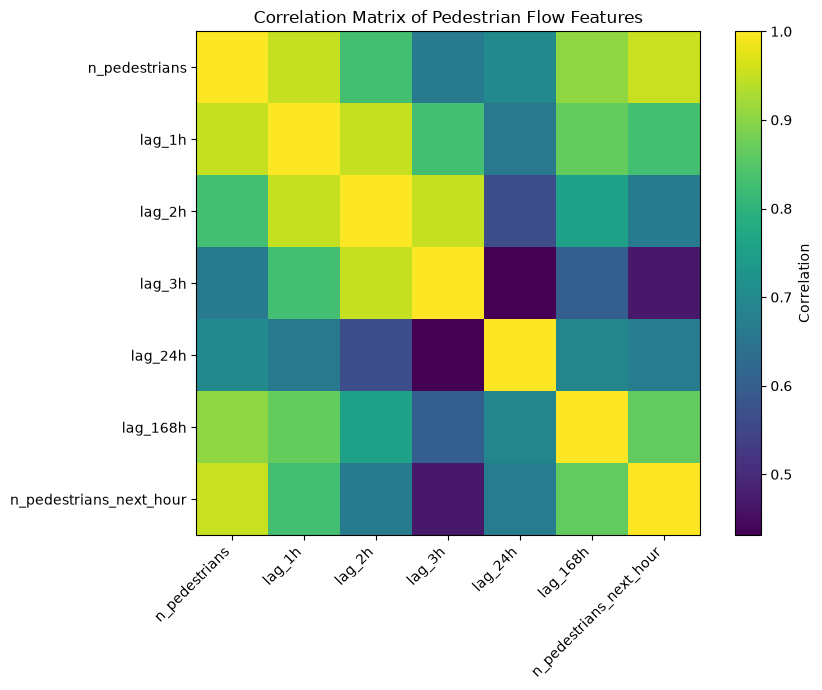

In [11]:
corr = df[lag_columns].corr()

plt.figure(figsize=(9, 7))

plt.imshow(corr, interpolation="nearest")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Correlation Matrix of Pedestrian Flow Features")

plt.tight_layout()
plt.show()

### Observation: Correlation Structure

The correlation matrix confirms that current pedestrian count has the strongest linear relationship with the next-hour pedestrian count. The 168-hour lag also shows a strong relationship, indicating a substantial weekly pattern. The 1-hour lag is another strong predictor, while the 3-hour lag has a comparatively weaker relationship with the target.

The lag variables are also correlated with one another, which indicates that pedestrian-flow history contains overlapping information. Feature importance and validation performance will therefore be used later to determine the most useful feature set.

In [12]:
weather_avg = (
    df.groupby("weather_condition")["n_pedestrians"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

weather_avg

,mean,count
weather_condition,,
sleet,2419.000000,1
partly-cloudy-day,1840.641627,8480
clear-day,1557.877277,3349
cloudy,1014.498872,10634
wind,982.812030,266
snow,980.156627,83
rain,848.315453,3915
fog,734.426667,300
partly-cloudy-night,300.524562,6962


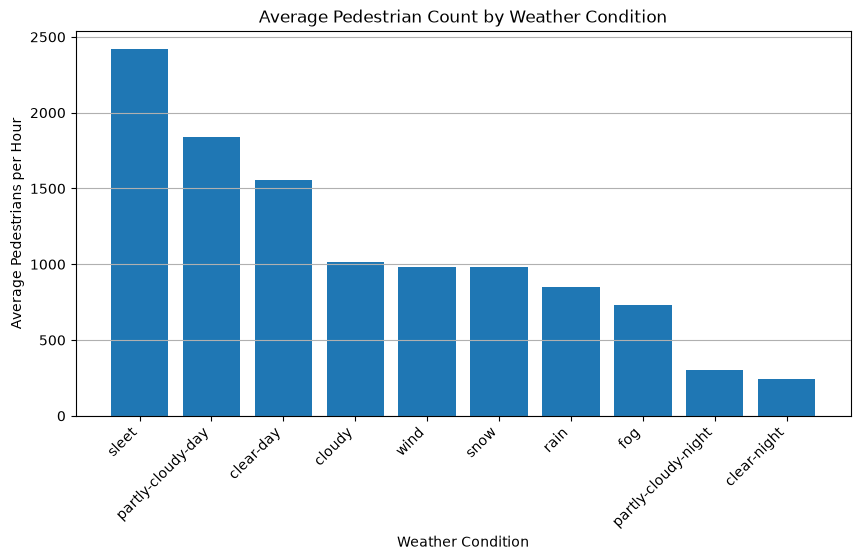

In [13]:
plt.figure(figsize=(10, 5))

plt.bar(
    weather_avg.index,
    weather_avg["mean"]
)

plt.xlabel("Weather Condition")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Average Pedestrian Count by Weather Condition")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")

plt.show()

In [14]:
incident_avg = (
    df.groupby("incidents")["n_pedestrians"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

incident_avg

,mean,count
incidents,,
no_incident,1042.748232,36613
laser_failure,669.041667,24
construction_site,316.285505,683


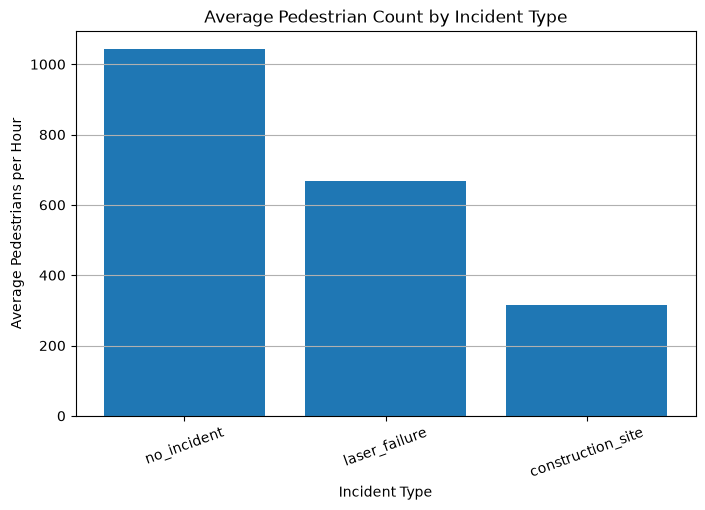

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    incident_avg.index,
    incident_avg["mean"]
)

plt.xlabel("Incident Type")
plt.ylabel("Average Pedestrians per Hour")
plt.title("Average Pedestrian Count by Incident Type")
plt.xticks(rotation=20)
plt.grid(axis="y")

plt.show()

In [1]:
high_counts = df[df["n_pedestrians"] > 5000]

print("Observations above 5000:", len(high_counts))

high_counts[
    [
        "datetime",
        "streetname",
        "n_pedestrians",
        "hour",
        "weekday",
        "weather_condition",
        "incidents",
    ]
].sort_values("n_pedestrians", ascending=False).head(20)

NameError: name 'df' is not defined

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../datasets/processed/train.csv")

df.head()

,datetime,streetname,hour,weekday,temperature,weather_condition,incidents,n_pedestrians,towards_ratio,lag_1h,lag_2h,lag_3h,lag_24h,lag_168h,target_datetime,n_pedestrians_next_hour
0,2022-10-06 00:00:00,Kaiserstrasse,0,Thursday,15,partly-cloudy-night,no_incident,26,0.576923,92.0,173.0,234.0,50.0,57.0,2022-10-06 01:00:00,13
1,2022-10-06 01:00:00,Kaiserstrasse,1,Thursday,15,partly-cloudy-night,no_incident,13,0.769231,26.0,92.0,173.0,11.0,32.0,2022-10-06 02:00:00,13
2,2022-10-06 02:00:00,Kaiserstrasse,2,Thursday,14,clear-night,no_incident,13,0.461538,13.0,26.0,92.0,6.0,4.0,2022-10-06 03:00:00,14
3,2022-10-06 03:00:00,Kaiserstrasse,3,Thursday,14,clear-night,no_incident,14,0.285714,13.0,13.0,26.0,15.0,14.0,2022-10-06 04:00:00,21
4,2022-10-06 04:00:00,Kaiserstrasse,4,Thursday,13,clear-night,no_incident,21,0.238095,14.0,13.0,13.0,23.0,16.0,2022-10-06 05:00:00,58


In [3]:
high_counts = df[df["n_pedestrians"] > 5000]

print("Observations above 5000:", len(high_counts))

high_counts[
    [
        "datetime",
        "streetname",
        "n_pedestrians",
        "hour",
        "weekday",
        "weather_condition",
        "incidents",
    ]
].sort_values("n_pedestrians", ascending=False).head(20)

Observations above 5000: 364


,datetime,streetname,n_pedestrians,hour,weekday,weather_condition,incidents
9345,2019-12-21 16:00:00,Schoenbornstrasse,8874,16,Saturday,partly-cloudy-day,no_incident
9176,2019-12-14 15:00:00,Schoenbornstrasse,8686,15,Saturday,partly-cloudy-day,no_incident
9344,2019-12-21 15:00:00,Schoenbornstrasse,8552,15,Saturday,partly-cloudy-day,no_incident
9010,2019-12-07 16:00:00,Schoenbornstrasse,8438,16,Saturday,cloudy,no_incident
9009,2019-12-07 15:00:00,Schoenbornstrasse,8338,15,Saturday,cloudy,no_incident
9177,2019-12-14 16:00:00,Schoenbornstrasse,8301,16,Saturday,partly-cloudy-day,no_incident
9392,2019-12-23 15:00:00,Schoenbornstrasse,8206,15,Monday,partly-cloudy-day,no_incident
9346,2019-12-21 17:00:00,Schoenbornstrasse,8205,17,Saturday,partly-cloudy-night,no_incident
8847,2019-11-30 15:00:00,Schoenbornstrasse,8132,15,Saturday,partly-cloudy-day,no_incident
8848,2019-11-30 16:00:00,Schoenbornstrasse,8131,16,Saturday,partly-cloudy-day,no_incident


In [4]:
df["n_pedestrians"].quantile([0.90, 0.95, 0.99, 0.995, 0.999])

0.900    2874.000
0.950    3476.050
0.990    4978.290
0.995    5530.215
0.999    6982.577
Name: n_pedestrians, dtype: float64

### Outlier Analysis

The pedestrian count distribution contains a small number of very high observations, with values reaching approximately 8,874 pedestrians per hour.

The extreme observations are concentrated in specific streets and time periods, particularly Schoenbornstrasse during afternoon hours and higher-footfall days. This suggests that the high values represent genuine periods of heavy pedestrian activity rather than random measurement errors.

Therefore, extreme pedestrian counts are retained in the dataset. Removing them could reduce the model's ability to learn and predict high-crowd situations.

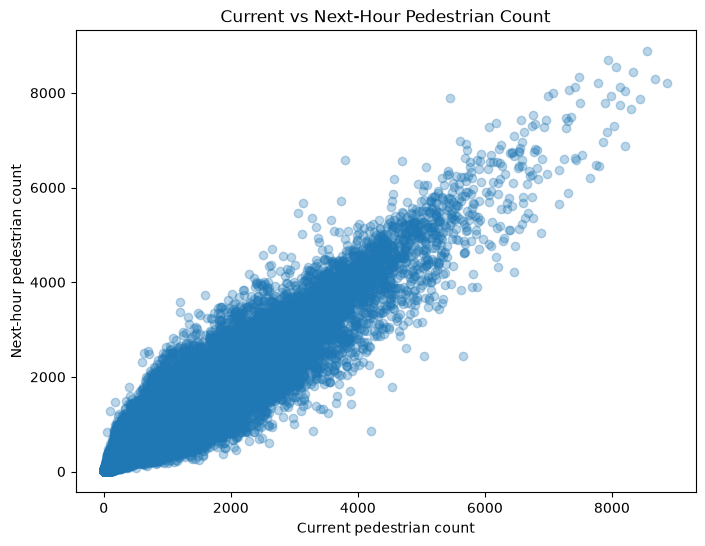

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["n_pedestrians"],
    df["n_pedestrians_next_hour"],
    alpha=0.3
)

plt.xlabel("Current pedestrian count")
plt.ylabel("Next-hour pedestrian count")
plt.title("Current vs Next-Hour Pedestrian Count")

plt.show()

### Current Count vs Next-Hour Count

The scatter plot shows a strong positive relationship between the current pedestrian count and the pedestrian count one hour later. Higher current pedestrian counts are generally associated with higher next-hour counts.

This supports the use of the current pedestrian count as an important feature for the forecasting model. However, the increasing spread at higher traffic levels indicates that prediction uncertainty becomes larger during high-footfall periods.

Therefore, additional temporal, location, weather, incident, and historical lag features may help improve predictions beyond using the current count alone.

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Load validation data
val_df = pd.read_csv("../datasets/processed/validation.csv")

# Baseline:
# assume the next hour will have the same pedestrian count
baseline_predictions = val_df["n_pedestrians"]

actual = val_df["n_pedestrians_next_hour"]

mae = mean_absolute_error(actual, baseline_predictions)
rmse = np.sqrt(mean_squared_error(actual, baseline_predictions))

print(f"Baseline MAE: {mae:.2f}")
print(f"Baseline RMSE: {rmse:.2f}")

Baseline MAE: 203.84
Baseline RMSE: 308.85


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Load train and validation data
train_df = pd.read_csv("../datasets/processed/train.csv")
val_df = pd.read_csv("../datasets/processed/validation.csv")

# Features used by the model
features = [
    "streetname",
    "hour",
    "weekday",
    "temperature",
    "weather_condition",
    "incidents",
    "n_pedestrians",
    "towards_ratio",
    "lag_1h",
    "lag_2h",
    "lag_3h",
    "lag_24h",
    "lag_168h"
]

target = "n_pedestrians_next_hour"

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val = val_df[target]

# Categorical and numerical features
categorical_features = [
    "streetname",
    "weekday",
    "weather_condition",
    "incidents"
]

numerical_features = [
    "hour",
    "temperature",
    "n_pedestrians",
    "towards_ratio",
    "lag_1h",
    "lag_2h",
    "lag_3h",
    "lag_24h",
    "lag_168h"
]

# Convert categorical features into numbers
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# Random Forest model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

# Complete preprocessing + model pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

# Train
pipeline.fit(X_train, y_train)

# Predict validation set
val_predictions = pipeline.predict(X_val)

# Evaluate
mae = mean_absolute_error(y_val, val_predictions)
rmse = np.sqrt(mean_squared_error(y_val, val_predictions))

print(f"Random Forest MAE: {mae:.2f}")
print(f"Random Forest RMSE: {rmse:.2f}")

Random Forest MAE: 76.76
Random Forest RMSE: 137.69


In [8]:
from sklearn.ensemble import GradientBoostingRegressor

# Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", gb_model)
    ]
)

# Train
gb_pipeline.fit(X_train, y_train)

# Predict
gb_predictions = gb_pipeline.predict(X_val)

# Evaluate
gb_mae = mean_absolute_error(y_val, gb_predictions)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_predictions))

print(f"Gradient Boosting MAE: {gb_mae:.2f}")
print(f"Gradient Boosting RMSE: {gb_rmse:.2f}")

Gradient Boosting MAE: 102.51
Gradient Boosting RMSE: 163.90


In [9]:
# Get feature names after preprocessing
feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance from Random Forest
importances = pipeline.named_steps["model"].feature_importances_

# Create a dataframe
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

# Sort by importance
importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df.head(15)

,feature,importance
25,numerical__n_pedestrians,0.908211
23,numerical__hour,0.063388
29,numerical__lag_3h,0.012361
28,numerical__lag_2h,0.005138
27,numerical__lag_1h,0.002093
30,numerical__lag_24h,0.001832
26,numerical__towards_ratio,0.001820
31,numerical__lag_168h,0.001499
24,numerical__temperature,0.001442
5,categorical__weekday_Saturday,0.000654


In [10]:
# Feature ablation experiment

# Model A: current pedestrian count only
features_a = [
    "n_pedestrians"
]

# Model B: current count + hour
features_b = [
    "n_pedestrians",
    "hour"
]

# Model C: all engineered features
features_c = features

def train_and_evaluate(feature_list, name):
    X_train_ab = train_df[feature_list]
    X_val_ab = val_df[feature_list]

    categorical = [
        col for col in feature_list
        if train_df[col].dtype == "object"
    ]

    numerical = [
        col for col in feature_list
        if col not in categorical
    ]

    preprocessor_ab = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            ),
            (
                "numerical",
                "passthrough",
                numerical
            )
        ]
    )

    model_ab = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    pipeline_ab = Pipeline(
        steps=[
            ("preprocessor", preprocessor_ab),
            ("model", model_ab)
        ]
    )

    pipeline_ab.fit(X_train_ab, y_train)

    predictions = pipeline_ab.predict(X_val_ab)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    return mae, rmse


mae_a, rmse_a = train_and_evaluate(features_a, "Current only")
mae_b, rmse_b = train_and_evaluate(features_b, "Current + hour")
mae_c, rmse_c = train_and_evaluate(features_c, "All features")

print("Feature Ablation Results")
print("------------------------")
print(f"Current only      → MAE: {mae_a:.2f}, RMSE: {rmse_a:.2f}")
print(f"Current + hour    → MAE: {mae_b:.2f}, RMSE: {rmse_b:.2f}")
print(f"All features      → MAE: {mae_c:.2f}, RMSE: {rmse_c:.2f}")

ValueError: could not convert string to float: 'Kaiserstrasse'

In [11]:
# Feature ablation experiment

features_a = [
    "n_pedestrians"
]

features_b = [
    "n_pedestrians",
    "hour"
]

features_c = features


def train_and_evaluate(feature_list):
    X_train_ab = train_df[feature_list]
    X_val_ab = val_df[feature_list]

    # Explicitly identify categorical features
    categorical = [
        col for col in feature_list
        if col in [
            "streetname",
            "weekday",
            "weather_condition",
            "incidents"
        ]
    ]

    # Everything else is numerical
    numerical = [
        col for col in feature_list
        if col not in categorical
    ]

    preprocessor_ab = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical
            ),
            (
                "numerical",
                "passthrough",
                numerical
            )
        ]
    )

    model_ab = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )

    pipeline_ab = Pipeline(
        steps=[
            ("preprocessor", preprocessor_ab),
            ("model", model_ab)
        ]
    )

    pipeline_ab.fit(X_train_ab, y_train)

    predictions = pipeline_ab.predict(X_val_ab)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))

    return mae, rmse


mae_a, rmse_a = train_and_evaluate(features_a)
mae_b, rmse_b = train_and_evaluate(features_b)
mae_c, rmse_c = train_and_evaluate(features_c)


print("Feature Ablation Results")
print("------------------------")
print(f"Current only   → MAE: {mae_a:.2f}, RMSE: {rmse_a:.2f}")
print(f"Current + hour → MAE: {mae_b:.2f}, RMSE: {rmse_b:.2f}")
print(f"All features   → MAE: {mae_c:.2f}, RMSE: {rmse_c:.2f}")

Feature Ablation Results
------------------------
Current only   → MAE: 231.68, RMSE: 343.81
Current + hour → MAE: 109.79, RMSE: 183.31
All features   → MAE: 76.76, RMSE: 137.69


### Feature Ablation Analysis

The feature ablation experiment was performed using the Random Forest model to determine the contribution of the engineered features.

Using only the current pedestrian count produced an MAE of 231.68 and RMSE of 343.81. Adding the hour of day substantially improved performance to an MAE of 109.79 and RMSE of 183.31.

Using the complete engineered feature set further reduced the error to an MAE of 76.76 and RMSE of 137.69.

These results demonstrate that the additional temporal, historical, location, weather, incident, and directional features provide meaningful predictive information. Therefore, the complete engineered feature set will be retained for subsequent model development.

In [12]:
from sklearn.ensemble import ExtraTreesRegressor

extra_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

extra_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", extra_model)
    ]
)

# Train
extra_pipeline.fit(X_train, y_train)

# Predict validation set
extra_predictions = extra_pipeline.predict(X_val)

# Evaluate
extra_mae = mean_absolute_error(y_val, extra_predictions)
extra_rmse = np.sqrt(mean_squared_error(y_val, extra_predictions))

print(f"Extra Trees MAE: {extra_mae:.2f}")
print(f"Extra Trees RMSE: {extra_rmse:.2f}")

Extra Trees MAE: 73.20
Extra Trees RMSE: 131.27


In [13]:
# Load the untouched test set
test_df = pd.read_csv("../datasets/processed/test.csv")

# Combine train + validation for final training
train_val_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

X_train_val = train_val_df[features]
y_train_val = train_val_df[target]

X_test = test_df[features]
y_test = test_df[target]

# Create a fresh Extra Trees model
final_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)

final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", final_model)
    ]
)

# Train on train + validation
final_pipeline.fit(X_train_val, y_train_val)

# Predict the untouched test set
test_predictions = final_pipeline.predict(X_test)

# Evaluate
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print(f"Final Test MAE: {test_mae:.2f}")
print(f"Final Test RMSE: {test_rmse:.2f}")

Final Test MAE: 70.43
Final Test RMSE: 122.43


### Final Model Evaluation

After comparing multiple models, Extra Trees Regressor produced the best validation performance and was selected as the final candidate model.

The model was retrained using the combined training and validation datasets and evaluated once on the previously untouched test set.

Final test performance:

- MAE: 70.43 pedestrians
- RMSE: 122.43 pedestrians

Compared with the naive baseline, which assumes that the next-hour count will equal the current count, the Extra Trees model substantially reduces prediction error.

These results demonstrate that the engineered temporal, historical, location, weather, incident, and directional features provide useful information for short-term pedestrian-flow forecasting.

This model is a Würzburg-data prototype for the Rahat Setu crowd-prediction component. It is not yet a live event model because Rahat Setu sensor/event data is not available at this stage.